# Landsat-8 Active Fire

Each sample is a 256 by 256 pixel patch at 30 m resolution. The image has 10 Landsat-8 bands, and we keep all of them. Landsat-8 band 8, the panchromatic band, is left out of this dataset. The mask is active fire in that same image: 1 for fire, 0 for no fire.

The full archive is about 192 GB. This notebook uses the authors' sample instead, 100 patches in a 231 MB zip. The loading code lives in `inspect_landsat.py` next to this notebook. It downloads that zip into `data/landsat8/` at the repo root the first time it runs.

The TIFF files do not store band names. The names next to each pair are the channel order from Pereira et al. 2021. The picture uses bands 7, 6, and 2 only so a 10-band image can be drawn on a screen. Fire is brightest in band 7.


In [1]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from inspect_landsat import (
    SAMPLE_COUNT,
    band_name_text,
    band_table,
    download_samples,
    extract_samples,
    false_color,
    load_pairs,
    sample_table,
)

archive = download_samples()
extract_samples(archive)
pairs = load_pairs(SAMPLE_COUNT)
image = pairs[0]["image"]
mask = pairs[0]["mask"]
print(f"Read {len(pairs)} image-and-mask pairs")
print(f"Image shape {image.shape} {image.dtype}")
print(f"Mask shape {mask.shape} {mask.dtype}")
print(band_name_text())


Using existing /Users/lokeshp/Projects/AIS_SkyAlert/skyalert/data/landsat8/samples.zip
Read 5 image-and-mask pairs
Image shape (256, 256, 10) uint16
Mask shape (256, 256) uint8
Band 1: Coastal aerosol
Band 2: Blue
Band 3: Green
Band 4: Red
Band 5: Near-infrared
Band 6: Shortwave infrared 1
Band 7: Shortwave infrared 2
Band 9: Cirrus
Band 10: Thermal infrared 1
Band 11: Thermal infrared 2


## Bands

One row per channel, in the order stored in the file. All ten are loaded. `min`, `max`, and `mean` are over every pixel in the five patches below. Values are the original 16-bit numbers, not scaled to reflectance.


In [2]:
bands = band_table(pairs)
bands

,channel,landsat_band,name,shape,dtype,min,max,mean
0,0,1,Coastal aerosol,256x256,uint16,9045,23070,10387.6
1,1,2,Blue,256x256,uint16,8192,23316,9552.4
2,2,3,Green,256x256,uint16,7217,23123,8647.9
3,3,4,Red,256x256,uint16,6259,24575,8073.4
4,4,5,Near-infrared,256x256,uint16,5376,28056,12272.1
5,5,6,Shortwave infrared 1,256x256,uint16,5114,65535,10797.5
6,6,7,Shortwave infrared 2,256x256,uint16,5143,65535,8397.9
7,7,9,Cirrus,256x256,uint16,4969,6410,5054.5
8,8,10,Thermal infrared 1,256x256,uint16,18344,61111,27938.6
9,9,11,Thermal infrared 2,256x256,uint16,16961,45506,25430.7


## Pairs

These are the five patches with the most fire pixels in the Schroeder mask, so the fire is visible. Murphy and Kumar-Roy masks are in the same download. Their fire-pixel counts are usually a bit higher, which is the disagreement the paper describes. The picture below uses the Schroeder mask.

In [3]:
samples = sample_table(pairs)
samples

,patch,image_shape,image_dtype,mask_shape,mask_dtype,schroeder_fire_pixels,murphy_fire_pixels,kumar_roy_fire_pixels
0,LC08_L1TP_001067_20200812_20200812_01_RT_p00441,256x256x10,uint16,256x256,uint8,118,142,137
1,LC08_L1TP_124017_20200826_20200826_01_RT_p00686,256x256x10,uint16,256x256,uint8,115,157,156
2,LC08_L1TP_173068_20200817_20200817_01_RT_p00672,256x256x10,uint16,256x256,uint8,41,52,53
3,LC08_L1TP_103068_20200823_20200823_01_RT_p00610,256x256x10,uint16,256x256,uint8,37,52,55
4,LC08_L1TP_170069_20200812_20200812_01_RT_p00330,256x256x10,uint16,256x256,uint8,34,44,47


## Image next to its fire mask

Left: bands 7, 6, and 2 stretched to the 2nd–98th percentile so the scene is visible. Middle: Schroeder mask. Red is fire, light grey is no fire. Right: the dimensions and all ten band names for that pair.


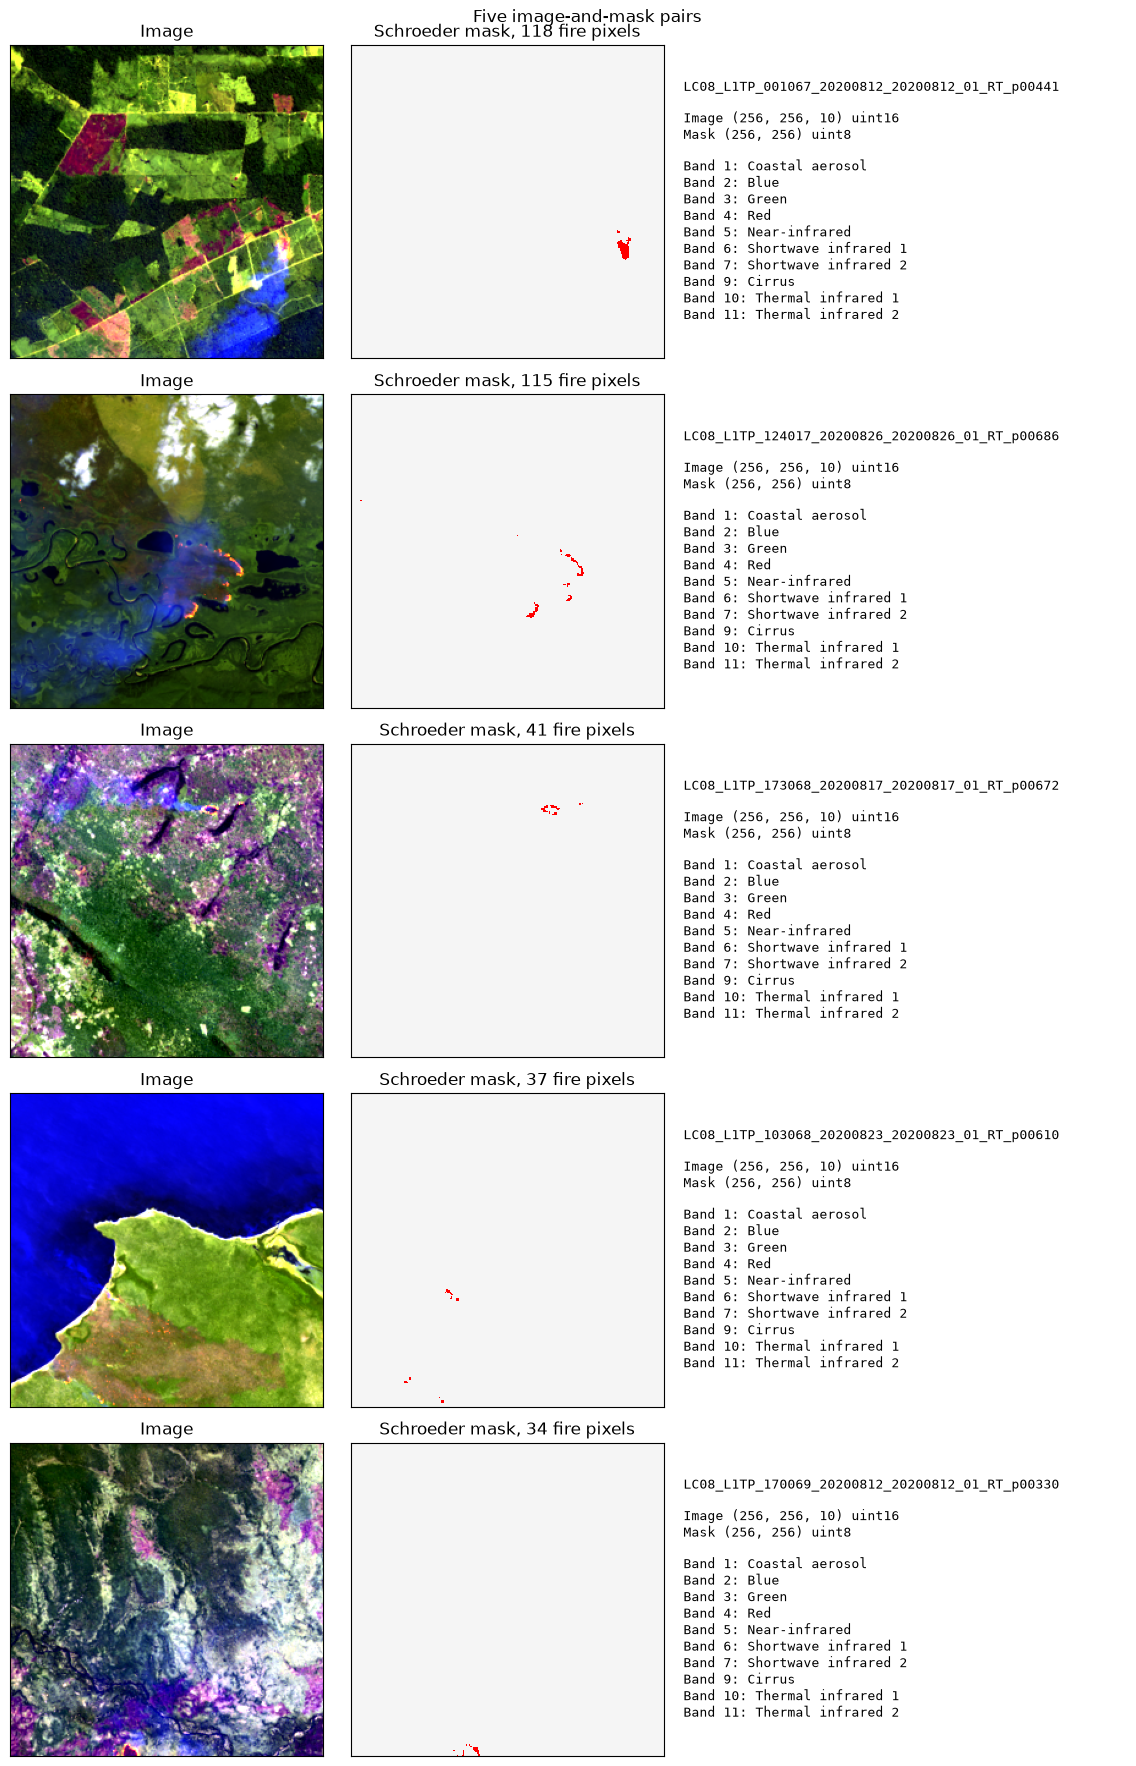

In [4]:
mask_colors = ListedColormap(["whitesmoke", "red"])
names = band_name_text()

fig, axes = plt.subplots(
    len(pairs),
    3,
    figsize=(12, 3.6 * len(pairs)),
    gridspec_kw={"width_ratios": [1, 1, 1.35]},
)
for row, pair in enumerate(pairs):
    image = pair["image"]
    mask = pair["mask"]
    axes[row, 0].imshow(false_color(image))
    axes[row, 0].set_title("Image")
    fire_pixels = pair["fire_pixels"]["schroeder"]
    axes[row, 1].imshow(mask, cmap=mask_colors, vmin=0, vmax=1, interpolation="nearest")
    axes[row, 1].set_title(f"Schroeder mask, {fire_pixels} fire pixels")
    for ax in axes[row, :2]:
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 2].axis("off")
    axes[row, 2].text(
        0.0,
        0.5,
        f"{pair['patch']}\n\nImage {image.shape} {image.dtype}\nMask {mask.shape} {mask.dtype}\n\n{names}",
        va="center",
        ha="left",
        family="monospace",
        fontsize=9,
    )
fig.suptitle("Five image-and-mask pairs")
plt.tight_layout()
fig.subplots_adjust(top=0.96)
